# Chapitre 14 - Exercices 14.7 à 14.12

Composantes principales, problèmes de Procrustes et formes moyennes, positionnement
multidimensionnel classique, ACP parcimonieuse.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.linalg import orthogonal_procrustes
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl import ch14_non_supervise as ns
set_style()

## Un lemme utile : maximiser une trace sous contrainte d'orthonormalité

Plusieurs exercices utilisent le résultat suivant (inégalité de Ky Fan).

**Lemme.** Soit $\mathbf{S}$ une matrice $n \times n$ symétrique de valeurs propres $\lambda_1 \ge
\dots \ge \lambda_n$ et de vecteurs propres orthonormés $e_1, \dots, e_n$. Pour toute matrice
$\mathbf{M}$ ($n \times q$) telle que $\mathbf{M}^T\mathbf{M} = \mathbf{I}_q$,

$$\operatorname{tr}(\mathbf{M}^T\mathbf{S}\mathbf{M}) \le \lambda_1 + \dots + \lambda_q ,$$

avec égalité pour $\mathbf{M} = (e_1, \dots, e_q)$.

*Preuve.* On écrit $\mathbf{S} = \sum_j \lambda_j e_j e_j^T$, d'où
$\operatorname{tr}(\mathbf{M}^T\mathbf{S}\mathbf{M}) = \sum_j \lambda_j \operatorname{tr}(\mathbf{M}^Te_je_j^T\mathbf{M})
= \sum_j \lambda_j w_j$ avec $w_j = \|\mathbf{M}^Te_j\|^2$.

* $w_j \ge 0$, et $w_j = e_j^T\mathbf{M}\mathbf{M}^Te_j \le \|e_j\|^2 = 1$ car $\mathbf{M}\mathbf{M}^T$ est
  un projecteur orthogonal (il est symétrique et $(\mathbf{M}\mathbf{M}^T)^2 = \mathbf{M}\mathbf{M}^T$).
* $\sum_j w_j = \operatorname{tr}(\mathbf{M}^T(\sum_j e_je_j^T)\mathbf{M}) = \operatorname{tr}(\mathbf{M}^T\mathbf{M}) = q$.

Maximiser $\sum_j \lambda_j w_j$ sous $0 \le w_j \le 1$, $\sum_j w_j = q$ revient à mettre tout le
poids sur les $q$ plus grands $\lambda_j$ : le maximum vaut $\lambda_1 + \dots + \lambda_q$. Il est
atteint par $\mathbf{M} = (e_1, \dots, e_q)$, pour qui $w_1 = \dots = w_q = 1$. $\square$

In [2]:
rng = np.random.RandomState(0)
A = rng.normal(size=(6, 6))
S = A + A.T
lam = np.sort(np.linalg.eigvalsh(S))[::-1]
essais = [np.trace(Q.T @ S @ Q) for Q in (np.linalg.qr(rng.normal(size=(6, 2)))[0] for _ in range(2000))]
print("max sur 2000 M aléatoires : %.4f  <=  lambda_1 + lambda_2 = %.4f" % (max(essais), lam[:2].sum()))

max sur 2000 M aléatoires : 11.7060  <=  lambda_1 + lambda_2 = 13.1184


## Exercice 14.7 : Composantes principales : estimation de $\mu$ et des $\lambda_i$

**Énoncé.** Établir (14.51) et (14.52) de la section 14.5.1 : dans le problème
$\min_{\mu, \{\lambda_i\}, \mathbf{V}_q} \sum_i \|x_i - \mu - \mathbf{V}_q\lambda_i\|^2$ (14.50), où
$\mathbf{V}_q$ ($p \times q$) a des colonnes orthonormées, on peut prendre $\hat\mu = \bar x$ et
$\hat\lambda_i = \mathbf{V}_q^T(x_i - \bar x)$. Montrer que $\hat\mu$ n'est pas unique et
caractériser la famille des solutions équivalentes.

### Étape 1 : $\lambda_i$ à $\mu$ et $\mathbf{V}_q$ fixés

Les termes de la somme sont indépendants : pour chaque $i$, on minimise $\|y_i - \mathbf{V}_q\lambda_i\|^2$
avec $y_i = x_i - \mu$. C'est une régression par moindres carrés de $y_i$ sur les colonnes de
$\mathbf{V}_q$ ; les équations normales donnent $\mathbf{V}_q^T\mathbf{V}_q\lambda_i = \mathbf{V}_q^Ty_i$, et
comme $\mathbf{V}_q^T\mathbf{V}_q = \mathbf{I}_q$ :

$$\hat\lambda_i = \mathbf{V}_q^T(x_i - \mu).$$

Le résidu est $(\mathbf{I} - \mathbf{P})(x_i - \mu)$ avec $\mathbf{P} = \mathbf{V}_q\mathbf{V}_q^T$, projecteur
orthogonal sur le sous-espace engendré par les colonnes de $\mathbf{V}_q$.

### Étape 2 : $\mu$ à $\mathbf{V}_q$ fixé

Il reste à minimiser $F(\mu) = \sum_i \|(\mathbf{I} - \mathbf{P})(x_i - \mu)\|^2$. Notons $\mathbf{Q} =
\mathbf{I} - \mathbf{P}$, projecteur ($\mathbf{Q}^T = \mathbf{Q}$, $\mathbf{Q}^2 = \mathbf{Q}$). Le gradient
est

$$\nabla F(\mu) = -2\sum_i \mathbf{Q}^T\mathbf{Q}(x_i - \mu) = -2N\,\mathbf{Q}(\bar x - \mu).$$

$F$ est convexe (somme de carrés de fonctions affines) : ses minimiseurs sont les $\mu$ qui
annulent le gradient, c'est-à-dire $\mathbf{Q}(\mu - \bar x) = 0$, soit $\mu - \bar x \in
\operatorname{Im}(\mathbf{V}_q)$.

### Conclusion et famille des solutions

Les solutions sont exactement

$$\hat\mu = \bar x + \mathbf{V}_q c, \quad c \in \mathbb{R}^q \text{ quelconque}, \qquad
\hat\lambda_i = \mathbf{V}_q^T(x_i - \hat\mu) = \mathbf{V}_q^T(x_i - \bar x) - c .$$

Le choix $c = 0$ donne (14.51)-(14.52). Géométriquement, $\mu$ n'est qu'un point **quelconque**
du sous-espace affine $\bar x + \operatorname{Im}(\mathbf{V}_q)$ ; changer de point revient à
translater l'origine des coordonnées $\lambda_i$ le long du sous-espace, sans changer les
approximations $\hat\mu + \mathbf{V}_q\hat\lambda_i = \bar x + \mathbf{P}(x_i - \bar x)$.

> **Remarque.** $\mathbf{V}_q$ n'est pas unique non plus : pour toute matrice orthogonale $\mathbf{R}$
> ($q \times q$), $\mathbf{V}_q\mathbf{R}$ engendre le même sous-espace et donne le même projecteur ;
> seuls les $\lambda_i$ changent ($\mathbf{R}^T\lambda_i$). Avec $\hat\mu = \bar x$, il reste à
> minimiser $\sum_i\|(\mathbf{I} - \mathbf{P})\tilde x_i\|^2 = \|\tilde{\mathbf{X}}\|_F^2 -
> \operatorname{tr}(\mathbf{V}_q^T\tilde{\mathbf{X}}^T\tilde{\mathbf{X}}\mathbf{V}_q)$ (14.53), donc à maximiser
> la trace : par le lemme, les $q$ premiers vecteurs propres de $\tilde{\mathbf{X}}^T\tilde{\mathbf{X}}$,
> c'est-à-dire les $q$ premiers vecteurs singuliers à droite de $\tilde{\mathbf{X}}$.

### Vérification numérique

In [3]:
rng = np.random.RandomState(1)
X = rng.normal(size=(100, 4)) @ rng.normal(size=(4, 4))
a = ns.acp(X, 2)
V = a["V"]


def critere(mu, Lam):
    return ((X - mu - Lam @ V.T) ** 2).sum()


xbar = X.mean(0)
for c in (np.zeros(2), np.array([3.0, -1.0]), np.array([-10.0, 5.0])):
    mu = xbar + V @ c
    Lam = (X - mu) @ V
    print("c = %-12s critère = %.6f" % (c, critere(mu, Lam)))
mu_mauvais = xbar + rng.normal(size=4)
print("mu hors du sous-espace : critère = %.6f" % critere(mu_mauvais, (X - mu_mauvais) @ V))

c = [0. 0.]      critère = 227.221085
c = [ 3. -1.]    critère = 227.221085
c = [-10.   5.]  critère = 227.221085
mu hors du sous-espace : critère = 651.499673


Toutes les solutions $\bar x + \mathbf{V}_q c$ donnent le même critère (minimal) ; un $\mu$ hors de
cette famille fait strictement moins bien.

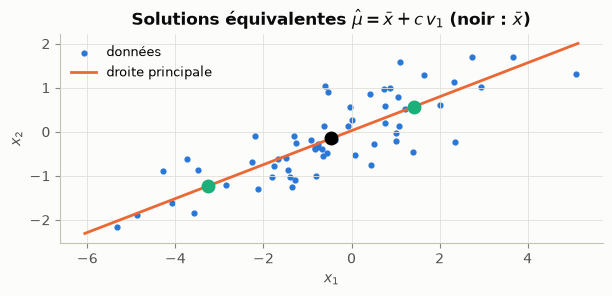

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.5))
rng = np.random.RandomState(2)
X2 = rng.normal(size=(60, 2)) @ np.array([[2.0, 0.8], [0.0, 0.5]])
a2 = ns.acp(X2, 1)
v = a2["V"][:, 0]
ax.scatter(*X2.T, s=12, color=BLUE, label="données")
tt = np.linspace(-6, 6, 2)
ax.plot(X2.mean(0)[0] + tt * v[0], X2.mean(0)[1] + tt * v[1], color=ORANGE, label="droite principale")
for c in (-3.0, 0.0, 2.0):
    m = X2.mean(0) + c * v
    ax.plot(*m, "o", ms=9, color=COLORS[2] if c else "k")
ax.set_aspect("equal")
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_title("Solutions équivalentes $\\hat\\mu = \\bar x + c\\, v_1$ (noir : $\\bar x$)")
ax.legend()
plt.show()

> **À retenir.** Dans (14.50), $\hat\lambda_i = \mathbf{V}_q^T(x_i - \hat\mu)$ (moindres carrés) et
> $\hat\mu$ est n'importe quel point du sous-espace affine $\bar x + \operatorname{Im}(\mathbf{V}_q)$ ;
> on choisit $\hat\mu = \bar x$ par commodité.

## Exercice 14.8 : Le problème de Procrustes, avec et sans échelle

**Énoncé.** Établir la solution (14.57) du problème de Procrustes
$\min_{\mu, \mathbf{R}} \|\mathbf{X}_2 - (\mathbf{X}_1\mathbf{R} + \mathbf{1}\mu^T)\|_F$ (14.56), avec
$\mathbf{R}$ orthogonale $p \times p$ ; puis celle du problème avec facteur d'échelle
$\min_{\beta, \mathbf{R}} \|\mathbf{X}_2 - \beta\mathbf{X}_1\mathbf{R}\|_F$ (14.58), $\beta > 0$.

### Rappels sur la norme de Frobenius

$\|\mathbf{A}\|_F^2 = \operatorname{tr}(\mathbf{A}^T\mathbf{A}) = \sum_{i,j} a_{ij}^2$. Elle est invariante
par multiplication par une matrice orthogonale : $\|\mathbf{A}\mathbf{R}\|_F^2 =
\operatorname{tr}(\mathbf{R}^T\mathbf{A}^T\mathbf{A}\mathbf{R}) = \operatorname{tr}(\mathbf{A}^T\mathbf{A}\mathbf{R}\mathbf{R}^T)
= \|\mathbf{A}\|_F^2$ (on a utilisé $\operatorname{tr}(\mathbf{B}\mathbf{C}) = \operatorname{tr}(\mathbf{C}\mathbf{B})$).

### Étape 1 : la translation

À $\mathbf{R}$ fixée, notons $\mathbf{E} = \mathbf{X}_2 - \mathbf{X}_1\mathbf{R}$, de lignes $e_i^T$. Le
critère vaut $\sum_i \|e_i - \mu\|^2$, minimal pour $\mu = \bar e$ (la moyenne minimise l'inertie,
cours 2), soit

$$\hat\mu = \bar x_2 - \mathbf{R}^T\bar x_1$$

(en vecteurs colonnes : la ligne moyenne de $\mathbf{X}_1\mathbf{R}$ est $\bar x_1^T\mathbf{R}$). Le livre
écrit $\hat\mu = \bar x_2 - \hat{\mathbf{R}}\bar x_1$ : c'est la même formule avec la convention où
les points sont transformés par $x \mapsto \mathbf{R}x$. Le critère devient alors
$\|\tilde{\mathbf{X}}_2 - \tilde{\mathbf{X}}_1\mathbf{R}\|_F^2$ avec les matrices centrées : on peut
oublier la translation.

### Étape 2 : la rotation

En développant et en utilisant l'invariance $\|\tilde{\mathbf{X}}_1\mathbf{R}\|_F = \|\tilde{\mathbf{X}}_1\|_F$ :

$$\|\tilde{\mathbf{X}}_2 - \tilde{\mathbf{X}}_1\mathbf{R}\|_F^2 = \|\tilde{\mathbf{X}}_2\|_F^2 + \|\tilde{\mathbf{X}}_1\|_F^2
 - 2\operatorname{tr}(\mathbf{R}^T\tilde{\mathbf{X}}_1^T\tilde{\mathbf{X}}_2).$$

Il faut **maximiser** $\operatorname{tr}(\mathbf{R}^T\mathbf{U}\mathbf{D}\mathbf{V}^T)$ où
$\tilde{\mathbf{X}}_1^T\tilde{\mathbf{X}}_2 = \mathbf{U}\mathbf{D}\mathbf{V}^T$ (SVD, $\mathbf{U}, \mathbf{V}$
orthogonales, $\mathbf{D} = \operatorname{diag}(d_1, \dots, d_p)$, $d_k \ge 0$). Par commutativité de
la trace, $\operatorname{tr}(\mathbf{R}^T\mathbf{U}\mathbf{D}\mathbf{V}^T) = \operatorname{tr}(\mathbf{Z}\mathbf{D})$ avec
$\mathbf{Z} = \mathbf{V}^T\mathbf{R}^T\mathbf{U}$, orthogonale (produit de matrices orthogonales).

Les coefficients d'une matrice orthogonale sont dans $[-1, 1]$ (ses colonnes sont unitaires),
donc

$$\operatorname{tr}(\mathbf{Z}\mathbf{D}) = \sum_k z_{kk} d_k \le \sum_k d_k = \operatorname{tr}(\mathbf{D}),$$

avec égalité si $\mathbf{Z} = \mathbf{I}$, c'est-à-dire $\mathbf{R}^T = \mathbf{V}\mathbf{U}^T$ :

$$\hat{\mathbf{R}} = \mathbf{U}\mathbf{V}^T \qquad (14.57).$$

La distance de Procrustes minimale vaut
$\sqrt{\|\tilde{\mathbf{X}}_1\|_F^2 + \|\tilde{\mathbf{X}}_2\|_F^2 - 2\operatorname{tr}(\mathbf{D})}$.

### Avec un facteur d'échelle (14.58)

On suppose les matrices centrées. À $\mathbf{R}$ fixée, le critère est un trinôme en $\beta$ :

$$\|\mathbf{X}_2 - \beta\mathbf{X}_1\mathbf{R}\|_F^2 = \|\mathbf{X}_2\|_F^2 - 2\beta\, t(\mathbf{R}) + \beta^2\|\mathbf{X}_1\|_F^2,
\qquad t(\mathbf{R}) = \operatorname{tr}(\mathbf{R}^T\mathbf{X}_1^T\mathbf{X}_2),$$

minimal en $\beta = t(\mathbf{R})/\|\mathbf{X}_1\|_F^2$ (si $t(\mathbf{R}) > 0$), où il vaut
$\|\mathbf{X}_2\|_F^2 - t(\mathbf{R})^2/\|\mathbf{X}_1\|_F^2$. Il faut donc maximiser $t(\mathbf{R})$ :
c'est le même problème qu'à l'étape 2, d'où le **même** $\hat{\mathbf{R}} = \mathbf{U}\mathbf{V}^T$, avec
$t(\hat{\mathbf{R}}) = \operatorname{tr}(\mathbf{D}) \ge 0$ et

$$\hat\beta = \frac{\operatorname{tr}(\mathbf{D})}{\|\mathbf{X}_1\|_F^2}.$$

### Vérification numérique

On compare notre solution à `scipy.linalg.orthogonal_procrustes` et à des matrices
orthogonales tirées au hasard.

In [ ]:
rng = np.random.RandomState(0)
X1 = rng.normal(size=(40, 3))
Rvrai = np.linalg.qr(rng.normal(size=(3, 3)))[0]
X2 = 0.7 * X1 @ Rvrai + [1.0, -2.0, 0.5] + 0.05 * rng.normal(size=(40, 3))
res = ns.procrustes(X1, X2, echelle=True)
R_sp, _ = orthogonal_procrustes(X1 - X1.mean(0), X2 - X2.mean(0))
print("R identique à SciPy :", np.allclose(res["R"], R_sp))
print("beta estimé : %.4f (vrai : 0,7)" % res["beta"])
A1, A2 = X1 - X1.mean(0), X2 - X2.mean(0)
crit = lambda R, b: ((A2 - b * A1 @ R) ** 2).sum()
aleat = min(crit(Q, res["beta"]) for Q in (np.linalg.qr(rng.normal(size=(3, 3)))[0] for _ in range(5000)))
print("critère optimal %.4f ; meilleur de 5000 rotations aléatoires %.4f" % (crit(res["R"], res["beta"]), aleat))

In [ ]:
betas = np.linspace(0.3, 1.1, 100)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(betas, [crit(res["R"], b) for b in betas], color=BLUE)
ax.axvline(res["beta"], color=ORANGE, ls="--", label="$\\hat\\beta = \\mathrm{tr}(D)/\\|X_1\\|_F^2$")
ax.set_xlabel("$\\beta$")
ax.set_ylabel("$\\|X_2 - \\beta X_1 \\hat R\\|_F^2$")
ax.set_title("Le critère est un trinôme en $\\beta$")
ax.legend()
plt.show()

> **À retenir.** Procrustes : centrer les deux nuages, faire la SVD $\tilde{\mathbf{X}}_1^T\tilde{\mathbf{X}}_2 =
> \mathbf{U}\mathbf{D}\mathbf{V}^T$ ; la rotation optimale est $\mathbf{U}\mathbf{V}^T$, l'échelle optimale
> $\operatorname{tr}(\mathbf{D})/\|\tilde{\mathbf{X}}_1\|_F^2$. L'argument clé : la trace de $\mathbf{Z}\mathbf{D}$
> avec $\mathbf{Z}$ orthogonale est au plus $\operatorname{tr}(\mathbf{D})$.

## Exercice 14.9 : Moyenne de Procrustes avec facteurs d'échelle

**Énoncé.** Écrire un algorithme pour résoudre
$\min_{\{\beta_\ell, \mathbf{R}_\ell\}_1^L, \mathbf{M}} \sum_{\ell=1}^L \|\beta_\ell\mathbf{X}_\ell\mathbf{R}_\ell - \mathbf{M}\|_F^2$
(version avec échelle de (14.115)). L'appliquer aux trois « S » et comparer à la figure 14.26.